Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_auc_score, roc_curve, auc, recall_score
)
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline
import scipy.stats as stats
import kagglehub
import os

Load data

In [2]:
path = kagglehub.dataset_download("shivamb/vehicle-claim-fraud-detection")

csv_files = sorted(f for f in os.listdir(path) if f.lower().endswith(".csv"))
if not csv_files:
    raise FileNotFoundError("No CSV found in downloaded dataset directory.")

df = pd.read_csv(os.path.join(path, csv_files[0]))
print(f"Loaded: {csv_files[0]} | {df.shape[0]} rows x {df.shape[1]} columns")


Loaded: fraud_oracle.csv | 15420 rows x 33 columns


Check out the data

In [3]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15420 entries, 0 to 15419
Data columns (total 33 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Month                 15420 non-null  object
 1   WeekOfMonth           15420 non-null  int64 
 2   DayOfWeek             15420 non-null  object
 3   Make                  15420 non-null  object
 4   AccidentArea          15420 non-null  object
 5   DayOfWeekClaimed      15420 non-null  object
 6   MonthClaimed          15420 non-null  object
 7   WeekOfMonthClaimed    15420 non-null  int64 
 8   Sex                   15420 non-null  object
 9   MaritalStatus         15420 non-null  object
 10  Age                   15420 non-null  int64 
 11  Fault                 15420 non-null  object
 12  PolicyType            15420 non-null  object
 13  VehicleCategory       15420 non-null  object
 14  VehiclePrice          15420 non-null  object
 15  FraudFound_P          15420 non-null

,WeekOfMonth,WeekOfMonthClaimed,Age,FraudFound_P,PolicyNumber,RepNumber,Deductible,DriverRating,Year
count,15420.000000,15420.000000,15420.000000,15420.000000,15420.000000,15420.000000,15420.000000,15420.000000,15420.000000
mean,2.788586,2.693969,39.855707,0.059857,7710.500000,8.483268,407.704280,2.487808,1994.866472
std,1.287585,1.259115,13.492377,0.237230,4451.514911,4.599948,43.950998,1.119453,0.803313
min,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,300.000000,1.000000,1994.000000
25%,2.000000,2.000000,31.000000,0.000000,3855.750000,5.000000,400.000000,1.000000,1994.000000
50%,3.000000,3.000000,38.000000,0.000000,7710.500000,8.000000,400.000000,2.000000,1995.000000
75%,4.000000,4.000000,48.000000,0.000000,11565.250000,12.000000,400.000000,3.000000,1996.000000
max,5.000000,5.000000,80.000000,1.000000,15420.000000,16.000000,700.000000,4.000000,1996.000000


Check for nulls and duplicates

In [4]:
print(f"Nulls: {df.isnull().sum().sum()}")
print(f"Duplicates: {df.duplicated().sum()}")
# zero of both

Nulls: 0
Duplicates: 0


Outlier check on numeric cols

In [5]:
numeric_cols = df.select_dtypes(include=[np.number]).columns

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_outliers = len(df[(df[col] < lower) | (df[col] > upper)])
    if n_outliers > 0:
        print(f"{col}: {n_outliers} outliers ({n_outliers/len(df)*100:.1f}%)")

# only deductible (3.8%), FraudFound_P (6%), and age (3.5%) have outliers

Age: 547 outliers (3.5%)
FraudFound_P: 923 outliers (6.0%)
Deductible: 582 outliers (3.8%)


Age versus fraud

In [6]:
print("Fraud rate for age 0:   ", f"{df[df['Age'] == 0]['FraudFound_P'].mean():.2%}")
print("Fraud rate age != 0:    ", f"{df[df['Age'] != 0]['FraudFound_P'].mean():.2%}")
print("Fraud rate under 21:    ", f"{df[df['Age'] < 21]['FraudFound_P'].mean():.2%}")
print("Fraud rate 21+:         ", f"{df[df['Age'] >= 21]['FraudFound_P'].mean():.2%}")

# age 0 has a noticeably higher fraud rate - leaving it in since it could be
# a real signal (fake/placeholder ages on fraudulent applications)


Fraud rate for age 0:    9.69%
Fraud rate age != 0:     5.91%
Fraud rate under 21:     11.06%
Fraud rate 21+:          5.84%


Age distribution plots

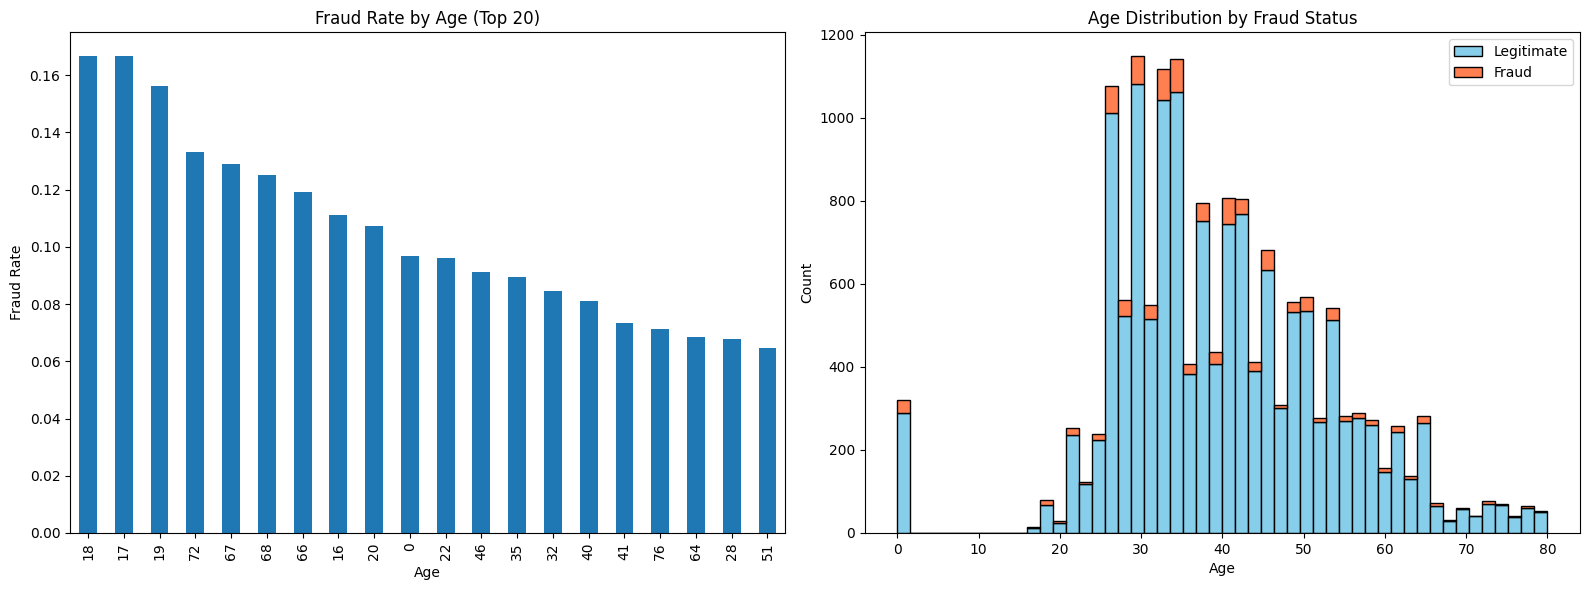

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

fraud_by_age = df.groupby('Age')['FraudFound_P'].mean().sort_values(ascending=False).head(20)
fraud_by_age.plot(kind='bar', ax=axes[0])
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Fraud Rate')
axes[0].set_title('Fraud Rate by Age (Top 20)')

fraud_ages = df[df['FraudFound_P'] == 1]['Age']
legit_ages = df[df['FraudFound_P'] == 0]['Age']
axes[1].hist([legit_ages, fraud_ages], bins=50, edgecolor='black',
             label=['Legitimate', 'Fraud'], color=['skyblue', 'coral'], stacked=True)
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Count')
axes[1].set_title('Age Distribution by Fraud Status')
axes[1].legend()

plt.tight_layout()
plt.show()

Train / test split

In [8]:
def prepare_data(dataframe):
    X = dataframe.drop('FraudFound_P', axis=1)
    y = dataframe['FraudFound_P']
    return train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

X_train, X_test, y_train, y_test = prepare_data(df)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Fraud rate - train: {y_train.mean():.2%}, test: {y_test.mean():.2%}")


Train: (10794, 32), Test: (4626, 32)
Fraud rate - train: 5.98%, test: 5.99%


Preprocessing

In [9]:
numeric_cols = X_train.select_dtypes(include=[np.number]).columns
categorical_cols = X_train.select_dtypes(exclude=[np.number]).columns

preprocess = ColumnTransformer(transformers=[
    ('num', 'passthrough', numeric_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
])

# class imbalance ratio - ~6% fraud
scale_pos_weight = len(y_train[y_train == 0]) / len(y_train[y_train == 1])
print(f"Class ratio (legit:fraud): {scale_pos_weight:.1f}:1")

Class ratio (legit:fraud): 15.7:1


Model comparison
(tried RF, LogReg, GradBoost, and XGBoost)
(XGBoost won on AUC - used that going forward)

In [10]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from imblearn.over_sampling import SMOTE

models = {
    "RandomForest": Pipeline([
        ('prep', preprocess),
        ('smote', SMOTE(random_state=42)),
        ('model', RandomForestClassifier(random_state=42))
    ]),
    "LogReg": Pipeline([
        ('prep', preprocess),
        ('smote', SMOTE(random_state=42)),
        ('model', LogisticRegression(max_iter=500))
    ]),
    "GradBoost": Pipeline([
        ('prep', preprocess),
        ('smote', SMOTE(random_state=42)),
        ('model', GradientBoostingClassifier(random_state=42))
    ]),
    "XGBoost": Pipeline([
        ('prep', preprocess),
        ('model', XGBClassifier(
            random_state=42, eval_metric='logloss',
            scale_pos_weight=scale_pos_weight,
            n_estimators=150, max_depth=5, learning_rate=0.1,
            subsample=0.9, colsample_bytree=0.8,
            reg_alpha=1, reg_lambda=1, min_child_weight=5
        ))
    ])
}

results = []
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    proba = pipe.predict_proba(X_test)[:, 1]
    preds = (proba >= 0.3).astype(int)
    results.append({
        "model": name,
        "recall@0.3": recall_score(y_test, preds),
        "fpr@0.3": confusion_matrix(y_test, preds)[0, 1] / y_test.value_counts()[0],
        "auc": roc_auc_score(y_test, proba)
    })

pd.DataFrame(results).sort_values('auc', ascending=False)

c:\Users\danri\OneDrive\Desktop\NEXISProject\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,model,recall@0.3,fpr@0.3,auc
3,XGBoost,0.935018,0.223040,0.945418
2,GradBoost,0.133574,0.016326,0.830205
0,RandomForest,0.083032,0.012647,0.813589
1,LogReg,0.920578,0.427455,0.797078


Final model
-dropped SMOTE - it was causing overfitting
-using scale_pos_weight instead, with heavier regularization

In [11]:
pipeline = Pipeline([
    ('prep', preprocess),
    ('model', XGBClassifier(
        random_state=42, eval_metric='logloss',
        scale_pos_weight=scale_pos_weight,
        n_estimators=100, max_depth=4, learning_rate=0.1,
        subsample=0.8, colsample_bytree=0.8,
        reg_alpha=2, reg_lambda=2, min_child_weight=20
    ))
])

pipeline.fit(X_train, y_train)
best_model = pipeline

Threshold Evaluation

In [12]:
y_pred_proba = best_model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_proba)

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
eval_rows = []

for t in thresholds:
    y_pred = (y_pred_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    eval_rows.append({
        'threshold': t,
        'fraud_caught': tp / (tp + fn),
        'false_alarm_rate': fp / (fp + tn),
        'precision': tp / (tp + fp) if (tp + fp) else 0,
        'f1': (2 * tp) / (2 * tp + fp + fn)
    })

eval_summary = pd.DataFrame(eval_rows)
eval_summary

,threshold,fraud_caught,false_alarm_rate,precision,f1
0,0.1,0.985560,0.507933,0.109992,0.197898
1,0.2,0.967509,0.429524,0.125468,0.222130
2,0.3,0.960289,0.396873,0.133534,0.234465
3,0.4,0.935018,0.359163,0.142230,0.246902
4,0.5,0.888087,0.293171,0.161736,0.273637
5,0.6,0.765343,0.188779,0.205227,0.323664
6,0.7,0.552347,0.083008,0.297665,0.386852
7,0.8,0.169675,0.012647,0.460784,0.248021


Picking threshold 0.7
- the lift metric points to 0.3 but that's way too aggressive on false alarms
- 0.7 is the right call given the cost asymmetry ($15K fraud vs $250 investigation)

In [13]:
threshold = 0.7
y_pred = (y_pred_proba >= threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

fraud_caught = tp / (tp + fn)
false_alarm = fp / (fp + tn)

print(f"AUC: {roc_auc:.3f}")
print(f"Fraud caught: {fraud_caught:.1%}, False alarms: {false_alarm:.1%}")
print(f"Caught {tp}/{tp+fn} fraud cases, flagged {fp} legitimate claims")


AUC: 0.882
Fraud caught: 55.2%, False alarms: 8.3%
Caught 153/277 fraud cases, flagged 361 legitimate claims


Overfit Check

In [14]:
cv_scores = cross_val_score(best_model, X_train, y_train, cv=5,
                            scoring='roc_auc', n_jobs=-1)

train_auc = roc_auc_score(y_train, best_model.predict_proba(X_train)[:, 1])

print(f"CV AUC: {cv_scores.mean():.3f} (+/- {cv_scores.std():.3f})")
print(f"Train AUC: {train_auc:.3f}")
print(f"Test AUC:  {roc_auc:.3f}")
print(f"Gap: {train_auc - roc_auc:.3f}")
# gap of ~0.06 is acceptable

CV AUC: 0.872 (+/- 0.005)
Train AUC: 0.945
Test AUC:  0.882
Gap: 0.063


Feature Importance

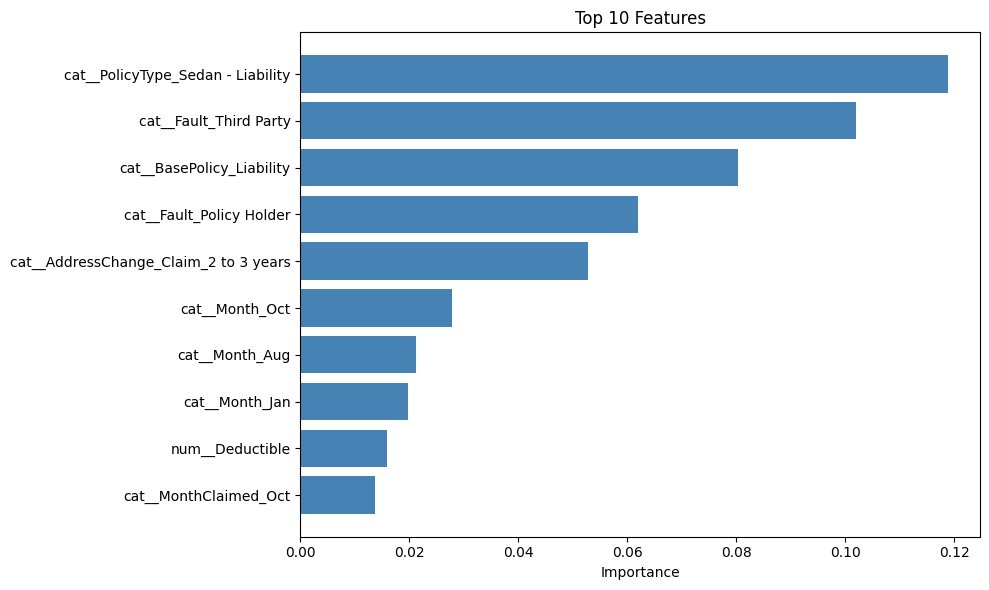

In [15]:
feature_names = preprocess.get_feature_names_out()
importances = best_model.named_steps['model'].feature_importances_

feat_imp = (pd.DataFrame({'feature': feature_names, 'importance': importances})
            .sort_values('importance', ascending=False)
            .reset_index(drop=True))

# top 10
top10 = feat_imp.head(10).iloc[::-1]
plt.figure(figsize=(10, 6))
plt.barh(top10['feature'], top10['importance'], color='steelblue')
plt.xlabel('Importance')
plt.title('Top 10 Features')
plt.tight_layout()
plt.savefig('outputs/feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

# liability policies + third party fault dominate - makes sense for staged accidents


ROC curve + threshold tradeoff

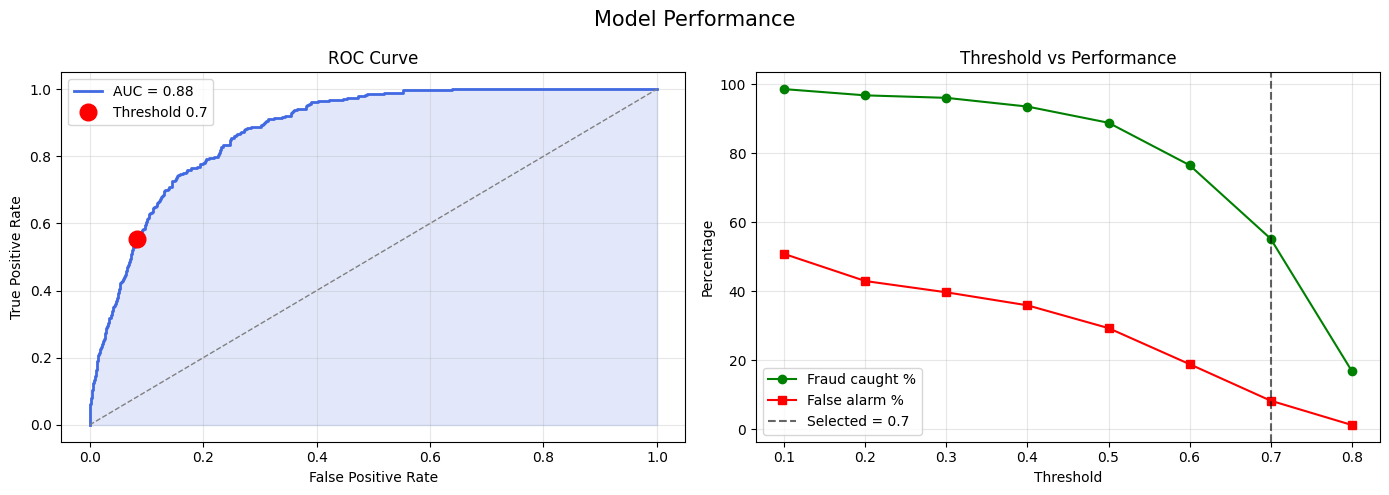

In [16]:
fpr_curve, tpr_curve, _ = roc_curve(y_test, y_pred_proba)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(fpr_curve, tpr_curve, lw=2, color='royalblue', label=f'AUC = {roc_auc:.2f}')
axes[0].fill_between(fpr_curve, tpr_curve, alpha=0.15, color='royalblue')
axes[0].plot([0, 1], [0, 1], lw=1, color='gray', linestyle='--')
axes[0].plot(false_alarm, fraud_caught, 'ro', markersize=12, label=f'Threshold {threshold}')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(eval_summary['threshold'], eval_summary['fraud_caught'] * 100,
             marker='o', label='Fraud caught %', color='green')
axes[1].plot(eval_summary['threshold'], eval_summary['false_alarm_rate'] * 100,
             marker='s', label='False alarm %', color='red')
axes[1].axvline(threshold, color='black', linestyle='--', alpha=0.6, label=f'Selected = {threshold}')
axes[1].set_xlabel('Threshold')
axes[1].set_ylabel('Percentage')
axes[1].set_title('Threshold vs Performance')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle('Model Performance', fontsize=15)
plt.tight_layout()
plt.savefig('outputs/roc_curve.png', dpi=300, bbox_inches='tight')
plt.show()

Confusion matrix

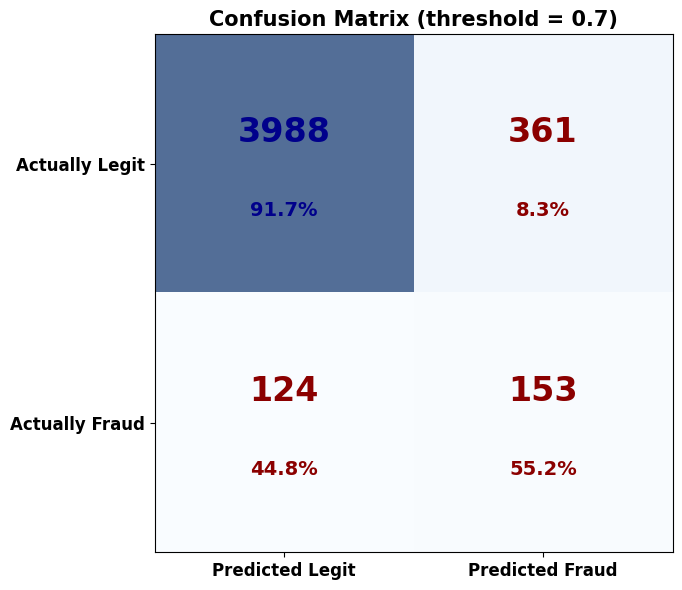

In [17]:
fig, ax = plt.subplots(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
im = ax.imshow(cm, cmap='Blues', alpha=0.7)

for i in range(2):
    for j in range(2):
        val = cm[i, j]
        pct = val / cm[i].sum() * 100
        # color by count - high counts are the correctly classified cells
        color = 'darkblue' if val > 1000 else 'darkred'
        ax.text(j, i - 0.12, f'{val}', ha='center', va='center',
                fontsize=24, fontweight='bold', color=color)
        ax.text(j, i + 0.18, f'{pct:.1f}%', ha='center', va='center',
                fontsize=14, fontweight='bold', color=color)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['Predicted Legit', 'Predicted Fraud'], fontsize=12, fontweight='bold')
ax.set_yticklabels(['Actually Legit', 'Actually Fraud'], fontsize=12, fontweight='bold')
ax.set_title(f'Confusion Matrix (threshold = {threshold})', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('outputs/confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

Cost analysis
- assumptions: $15K avg fraud payout, $250 per investigation

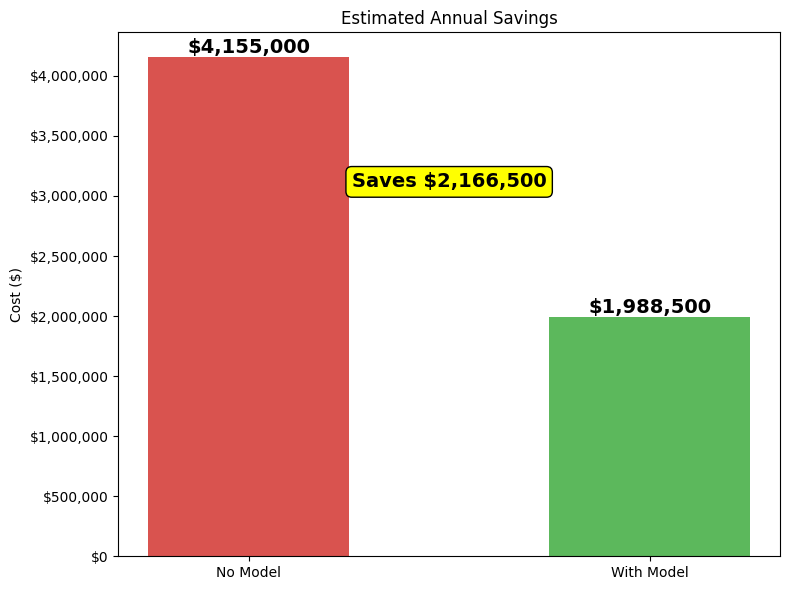

Without model: $4,155,000
With model:    $1,988,500
Savings:       $2,166,500


In [18]:
AVG_FRAUD = 15000
INVESTIGATION = 250  # industry estimate, range is ~$150-400

# without model: every fraud claim gets paid out
cost_no_model = (tp + fn) * AVG_FRAUD

# with model: missed fraud still gets paid, everything flagged gets investigated
cost_with_model = (fn * AVG_FRAUD) + ((tp + fp) * INVESTIGATION)

savings = cost_no_model - cost_with_model

fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(['No Model', 'With Model'], [cost_no_model, cost_with_model],
              color=['#d9534f', '#5cb85c'], width=0.5)

for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f'${bar.get_height():,.0f}', ha='center', va='bottom',
            fontsize=14, fontweight='bold')

ax.text(0.5, (cost_no_model + cost_with_model) / 2,
        f'Saves ${savings:,.0f}', ha='center', fontsize=14, fontweight='bold',
        bbox=dict(boxstyle='round', facecolor='yellow'))

ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:,.0f}'))
ax.set_ylabel('Cost ($)')
ax.set_title('Estimated Annual Savings')
plt.tight_layout()
plt.savefig('outputs/cost_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Without model: ${cost_no_model:,.0f}")
print(f"With model:    ${cost_with_model:,.0f}")
print(f"Savings:       ${savings:,.0f}")